In [31]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [32]:
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
import sys
sys.path.insert(0, r"c:\users\arthu\documents\swittz-epfl\phd\code\lib\site-packages")
sys.path.append('../')
from pygraphon.norm import MseProbaEdge, MaeProbaEdge, AUCEdge, AUPRCEdge
from pygraphon.plots.plot_matrices import spy

from pygraphon.estimators import SAS, TV_FL, FusedLasso

In [33]:
from pygraphon.estimators import FusedLasso
from pygraphon.graphons import common_graphons
from pygraphon.norm import JensenShannonDivergenceDistance, EarthMoversDistance, HellingerDistance, SimpleDifferenceDistance
n = 50
estimators = {g: {"SAS": None, "TV_FLJS": None, "EMD": None} for _,g in enumerate(common_graphons.values())}

for j,g in enumerate(common_graphons.values()):
    adj_mat = g.draw(n=n, exchangeable=False)
    est_FL = FusedLasso()
    est_FL.fit(adj_mat)



                                     CVXPY                                     
                                     v1.4.2                                    
(CVXPY) Apr 05 02:15:21 PM: Your problem has 7400 variables, 2 constraints, and 0 parameters.
(CVXPY) Apr 05 02:15:21 PM: It is compliant with the following grammars: DCP, DQCP
(CVXPY) Apr 05 02:15:21 PM: (If you need to solve this problem multiple times, but with different data, consider using parameters.)
(CVXPY) Apr 05 02:15:21 PM: CVXPY will first compile your problem; then, it will invoke a numerical solver to obtain a solution.
(CVXPY) Apr 05 02:15:21 PM: Your problem is compiled with the CPP canonicalization backend.
-------------------------------------------------------------------------------
                                  Compilation                                  
-------------------------------------------------------------------------------
(CVXPY) Apr 05 02:15:21 PM: Compiling problem (target solver=OSQP).
(C

In [34]:
from pygraphon.graphons import common_graphons
from pygraphon.norm import JensenShannonDivergenceDistance, EarthMoversDistance, HellingerDistance, SimpleDifferenceDistance
n = 100
estimators = {g: {"SAS": None, "TV_FLJS": None, "EMD": None} for _,g in enumerate(common_graphons.values())}

for j,g in enumerate(common_graphons.values()):
    adj_mat = g.draw(n=n, exchangeable=False)
    est_sas = SAS()
    est_sas.fit(adj_mat)
    est_tv_fl = FusedLasso()
    est_tv_fl.fit(adj_mat)
    estimators[g]["SAS"] = est_sas
    estimators[g]["TV_FL"] = est_tv_fl


                                     CVXPY                                     
                                     v1.4.2                                    
(CVXPY) Apr 05 02:28:38 PM: Your problem has 29800 variables, 2 constraints, and 0 parameters.
(CVXPY) Apr 05 02:28:38 PM: It is compliant with the following grammars: DCP, DQCP
(CVXPY) Apr 05 02:28:38 PM: (If you need to solve this problem multiple times, but with different data, consider using parameters.)
(CVXPY) Apr 05 02:28:38 PM: CVXPY will first compile your problem; then, it will invoke a numerical solver to obtain a solution.
(CVXPY) Apr 05 02:28:38 PM: Your problem is compiled with the CPP canonicalization backend.
-------------------------------------------------------------------------------
                                  Compilation                                  
-------------------------------------------------------------------------------
(CVXPY) Apr 05 02:28:38 PM: Compiling problem (target solver=OSQP).
(

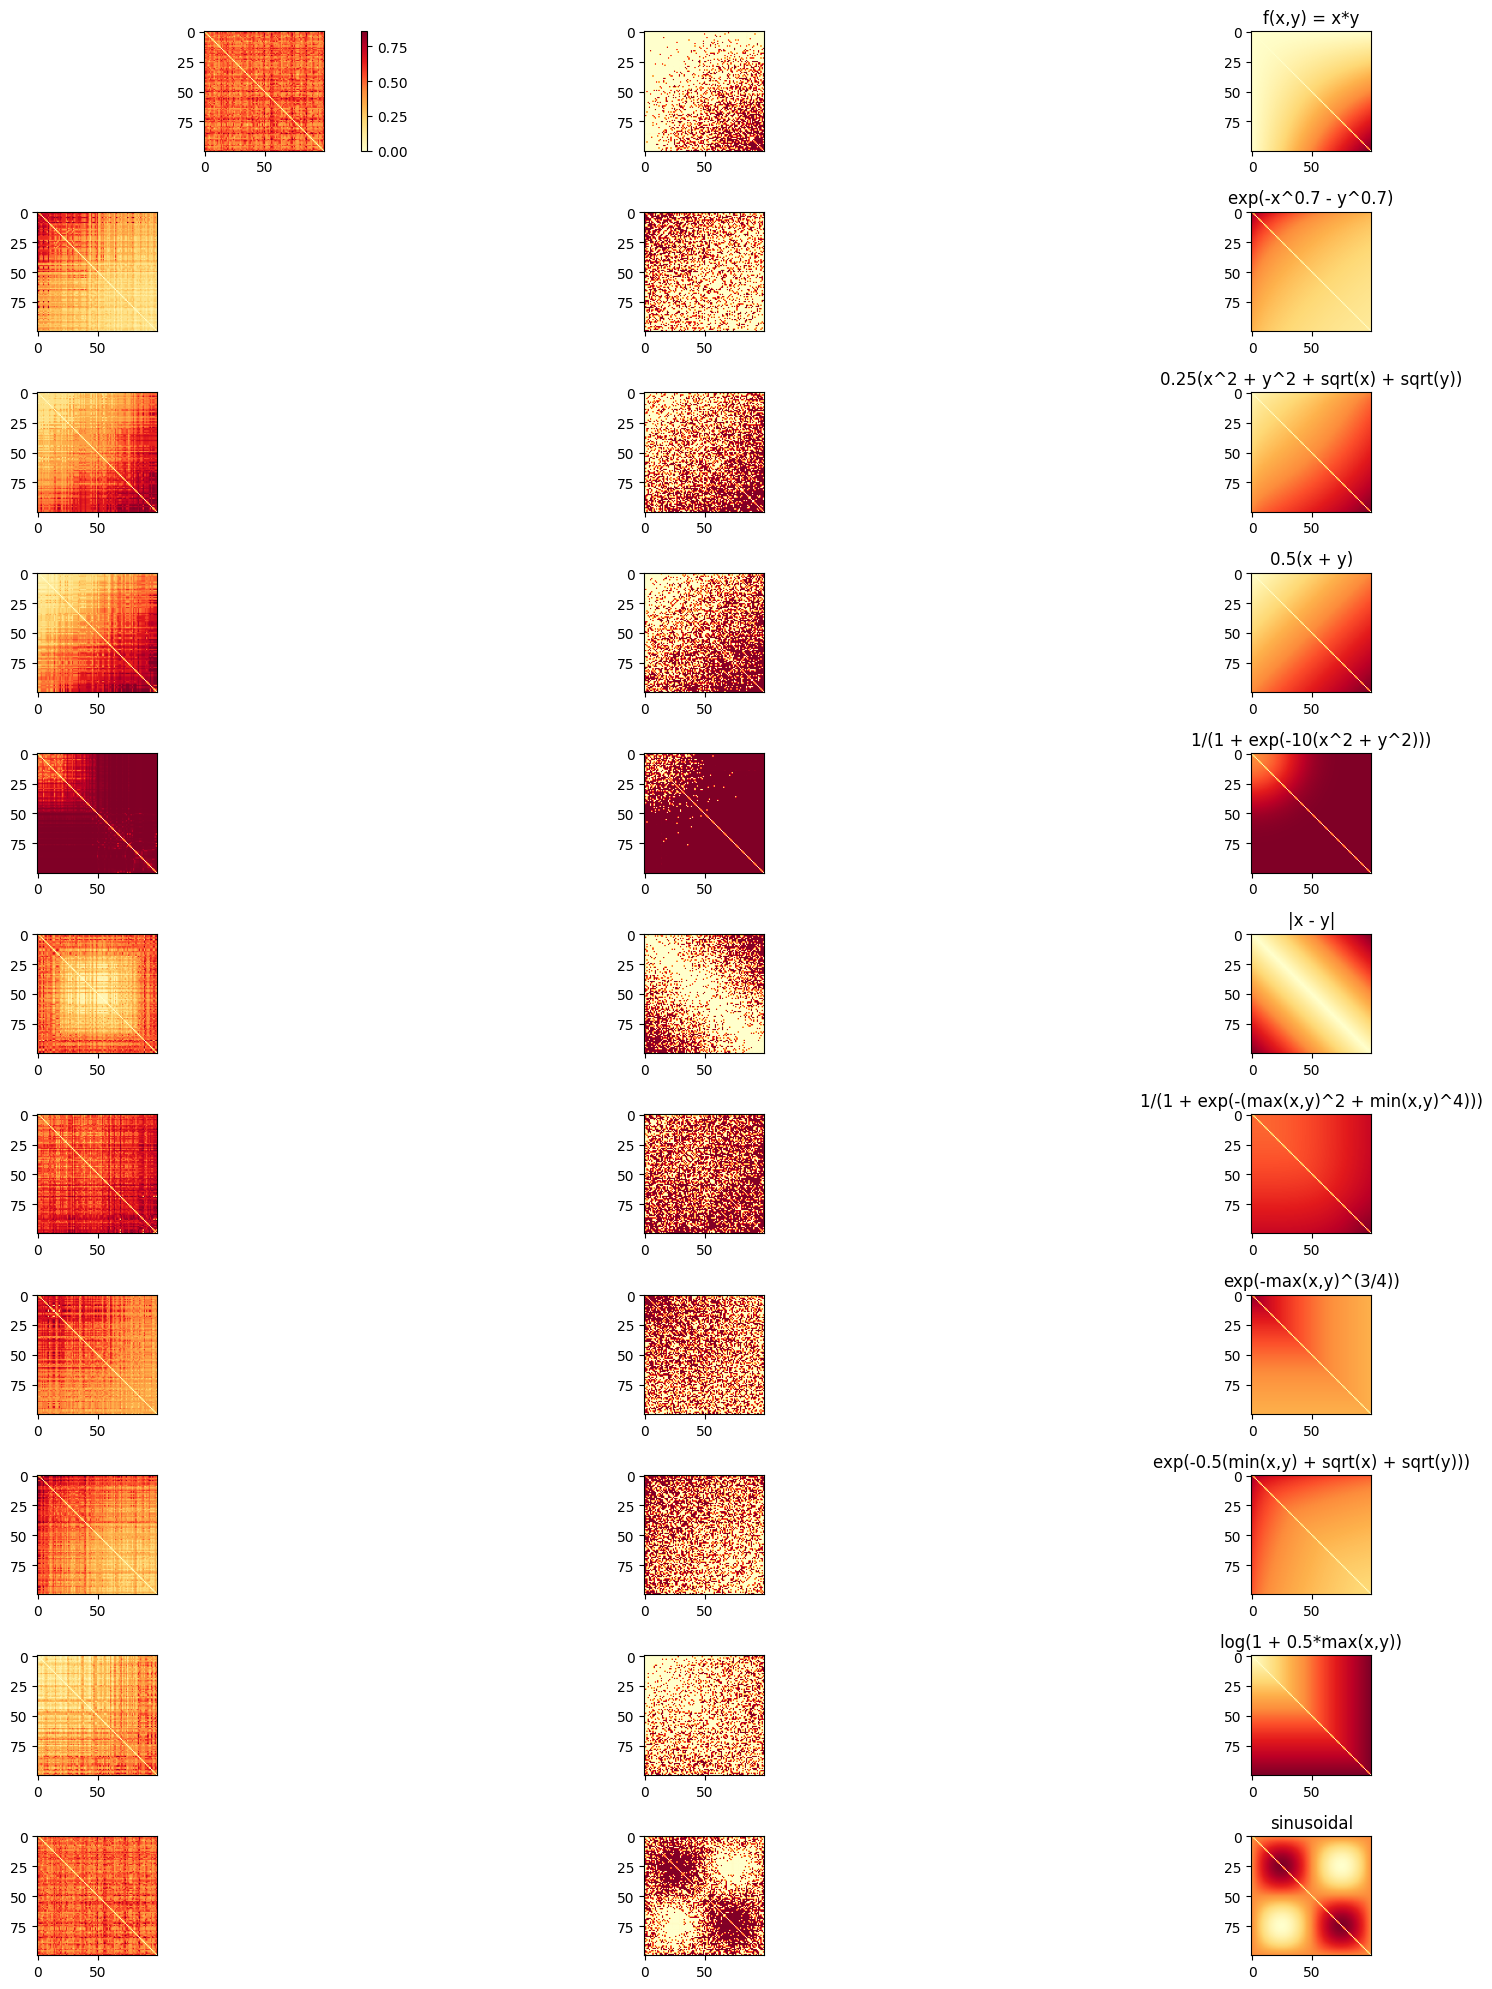

In [37]:
from palettable.colorbrewer.sequential import YlOrRd_9
# To get the colors as a list of RGB tuples:
colors = YlOrRd_9.mpl_colors
hex_colors = YlOrRd_9.hex_colors
import matplotlib.cm as cm
import matplotlib.colors as colors
cmap = cm.get_cmap('YlOrRd')
fig, axes = plt.subplots(nrows=len(common_graphons.values()), ncols=3, figsize=(20, 20))
for j,g in enumerate(common_graphons.values()):
    axes[j,0].imshow(estimators[g]["SAS"].get_edge_connectivity(), cmap = cmap)
    axes[j,1].imshow(estimators[g]["TV_FL"].get_edge_connectivity(), cmap = cmap)
    axes[j,2].imshow(g.get_edge_probabilities(n,False,True), cmap = cmap)
    axes[j,2].set_title(str(g))
plt.colorbar(axes[0,0].imshow(estimators[g]["SAS"].get_edge_connectivity(), cmap = cmap), ax=axes[0,0])
plt.tight_layout()
plt.show()